# **Module 03: Bivariate Descriptive Statistics**

---

## 📌 Overview

**Bivariate Descriptive Statistics** focuses on the simultaneous analysis of **two variables** to investigate whether there is an association, dependency, or joint pattern between them. While univariate analysis reveals the isolated behavior of each attribute, the bivariate approach allows answering essential business and data science questions — such as checking whether an increase in one metric accompanies the growth of another, or whether the distribution of a numerical variable changes across different categories.

In this notebook, we will explore the numerical and visual techniques suited for each possible combination of variable types.

---

## 🎯 Learning Objectives

By the end of this module, you will be able to:

* **Analyze relationships between two qualitative variables** using contingency tables (*crosstabs*), joint, marginal, and conditional frequencies, as well as measures of association (such as Chi-square and Cramér's V).
* **Compare a quantitative variable across different qualitative groups** using segmented descriptive statistics and comparative visualizations.
* **Measure the direction and strength of the relationship between two quantitative variables** using covariance and correlation coefficients (Pearson, Spearman, and Kendall).
* **Distinguish correlation from causation**, identifying spurious relationships and confounding variables.
* **Build and interpret bivariate charts** (grouped/stacked bar charts, comparative boxplots, scatter plots, and heatmaps).

---

## 🧭 Module Structure

1. **Qualitative vs. Qualitative** — Contingency tables, row/column profiles, and measures of association.
2. **Qualitative vs. Quantitative** — Comparing summary statistics by category and analyzing variation across groups.
3. **Quantitative vs. Quantitative** — Covariance, linear correlation (Pearson), and monotonic correlation (Spearman and Kendall).
4. **Correlation vs. Causation** — Common pitfalls when interpreting relationships between variables.
5. **Bivariate Graphical Analysis** — Scatter plots, grouped boxplots, violin plots, and heatmaps.
6. **Hands-on Python** — Complete practical application using `pandas`, `numpy`, `scipy.stats`, `matplotlib`, and `seaborn`.

---

## 🛠️ Technical Requirements

* Prior knowledge of **Variable Types and Measurement Scales** (*Module 01*) and **Univariate Descriptive Statistics** (*Module 02*).
* Python environment configured with: `numpy`, `pandas`, `scipy`, `matplotlib`, and `seaborn`.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
import statistics as st
import scipy.stats as stats
from scipy.stats import chi2_contingency, spearmanr

## **Association Between Two Qualitative Variables**

`NOTE:` *The datasets used in this chapter (`.dta` files) accompany the book and should be placed in the `dados/` folder alongside the notebooks.*

### **Joint Frequency Distribution Tables**

Also called contingency tables, they cross-tabulate the categories of two variables and display the frequency of each combination.

In [3]:
data = pd.read_stata("./datasets/PlanHealth.dta")
data.head()

,operadora,satisfacao
0,total health,baixo
1,total health,baixo
2,total health,baixo
3,total health,baixo
4,total health,baixo


### **Measures of Association**
The main measures are:

* `Chi-square` ($\chi^2$): measures the association between qualitative variables.
* `Phi coefficient`, `contingency coefficient`, and `Cramér's V`: measures based on $\chi^2$ for nominal variables.
* `Spearman's rank correlation coefficient`: for ordinal variables.

In [4]:
# Contingency table with totals
contingency = pd.crosstab(data['operadora'], data['satisfacao'], margins=True, margins_name='Total')
contingency

satisfacao,alto,baixo,medio,Total
operadora,,,,
saude plena,42,8,15,65
total health,10,40,20,70
viva bem,20,10,35,65
Total,72,58,70,200


In [5]:
# Chi-square test
contingency2 = pd.crosstab(data['operadora'], data['satisfacao'])
c, p, dof, expected = chi2_contingency(contingency2)
print(f"Chi-square: {np.round(c, 2)} | p-value: {np.round(p, 4)}")

Chi-square: 64.03 | p-value: 0.0


#### **Chi-Square**
Measures the discrepancy between the observed contingency table and the expected contingency table (assuming there were no association between the variables).

$\chi^2 = \sum_{i=1}^I\sum_{j=1}^J\frac{(O_{ij} - E_{ij})^2}{E_{ij}}$

The larger the $\chi^2$ statistic (and the smaller the p-value), the stronger the evidence of association. The table below, showing row percentages, helps visualize where the differences between health plan providers lie.

In [6]:
# Contingency table in row percentages
contingency = pd.crosstab(data['operadora'], data['satisfacao'], normalize='index')
contingency = np.round(contingency * 100, 2)
contingency["Total"] = contingency.sum(axis=1)
contingency

satisfacao,alto,baixo,medio,Total
operadora,,,,
saude plena,64.62,12.31,23.08,100.01
total health,14.29,57.14,28.57,100.00
viva bem,30.77,15.38,53.85,100.00


#### **Phi Coefficient**
The simplest measure of association for nominal variables.

$\phi = \sqrt{\frac{\chi^2}{n}}$

`NOTE:` *Phi ranges between 0 and 1 only when the contingency table is 2 x 2.*

In [7]:
data = pd.read_stata("./datasets/Segmentation_Market.dta")
data.head()

,roupa,região
0,gravata,sul
1,camisa polo,norte
2,camisa social,sul
3,calça,norte
4,gravata,sul


In [8]:
# Phi coefficient
contingency2 = pd.crosstab(data['roupa'], data['região'])
c, p, dof, expected = chi2_contingency(contingency2)
phi = np.round(np.sqrt(c / len(data["roupa"])), 2)
phi

np.float64(0.5)

#### **Pearson's Contingency Coefficient**
Also a measure of association between nominal variables.

$C = \sqrt{\frac{\chi^2}{n + \chi^2}}$

In [9]:
# Pearson's contingency coefficient
contingency2 = pd.crosstab(data['roupa'], data['região'])
c, p, dof, expected = chi2_contingency(contingency2)
C = np.round(np.sqrt(c / (len(data["roupa"]) + c)), 2)
C

np.float64(0.44)

#### **Cramér's V**

$V = \sqrt{\frac{\chi^2}{n\cdot(q-1)}}$

where $q$ is the smaller value between the number of rows and the number of columns in the table.

`NOTE:` *When the contingency table is 2 x 2, $V = \phi$.*

In [10]:
# Cramér's V
contingency2 = pd.crosstab(data['roupa'], data['região'])
c, p, dof, expected = chi2_contingency(contingency2)

q = min(contingency2.shape)
V = np.round(np.sqrt(c / (len(data["roupa"]) * (q - 1))), 2)
V

np.float64(0.35)

#### **Spearman's Correlation Coefficient**
Measures the association between two ordinal variables based on the difference $d_k$ between the ranks of each observation.

$r_{sp} = 1 - \frac{6\sum_{k=1}^n{d_{k}^2}}{n(n^2 - 1)}$

$r_{sp} = -1$ perfect negative association <p>
$r_{sp} = 0$ no association <p>
$r_{sp} = 1$ perfect positive association <p>

In [11]:
data = pd.read_stata("datasets/Notes.dta")
data.head()

,simulação,finanças
0,5,6
1,7,5
2,8,8
3,6,9
4,4,2


In [12]:
np.round(stats.spearmanr(data)[0], 2)

np.float64(0.76)

## **Association Between Two Quantitative Variables**

### **Graphical Representation via Scatter Plot**

The charts below simulate different relationships between $X$ and $Y$: strong positive, moderate positive, moderate negative, strong negative, and, in the last two, no apparent relationship.

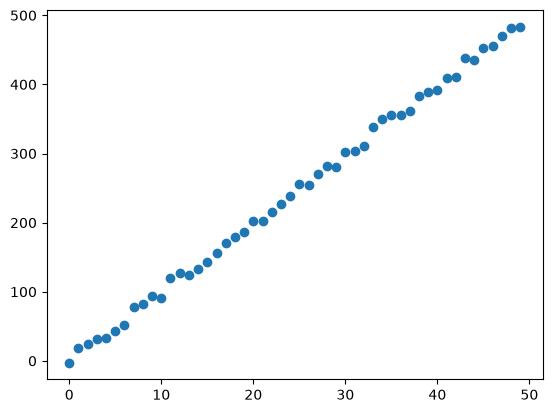

In [13]:
np.random.seed(42)

data_1 = pd.DataFrame()
data_1["X"] = np.arange(50)
delta = np.random.uniform(-10, 10, data_1["X"].size)
data_1["Y"] = 10 * data_1["X"] + delta

plt.scatter(y=data_1["Y"], x=data_1["X"]);

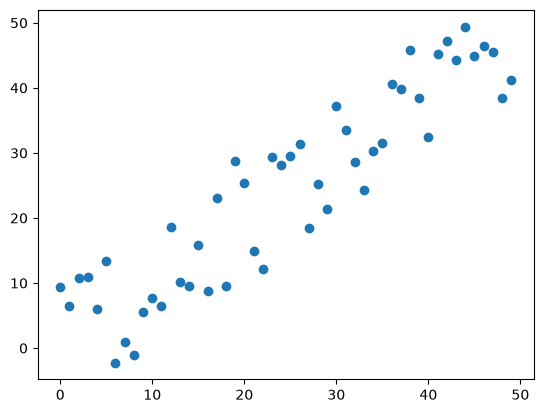

In [14]:
data_2 = pd.DataFrame()
data_2["X"] = np.arange(50)
delta = np.random.uniform(-10, 10, data_2["X"].size)
data_2["Y"] = data_2["X"] + delta

plt.scatter(y=data_2["Y"], x=data_2["X"]);

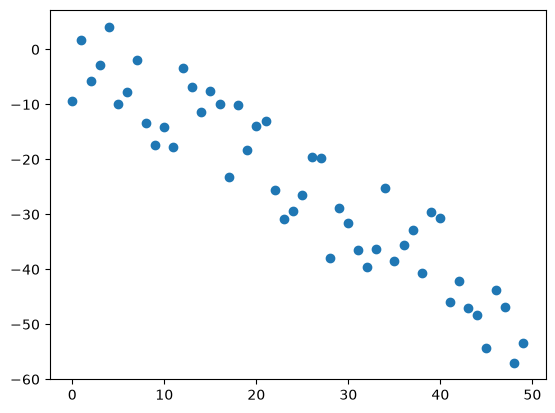

In [15]:
data_3 = pd.DataFrame()
data_3["X"] = np.arange(50)
delta = np.random.uniform(-10, 10, data_3["X"].size)
data_3["Y"] = -data_3["X"] + delta

plt.scatter(y=data_3["Y"], x=data_3["X"]);

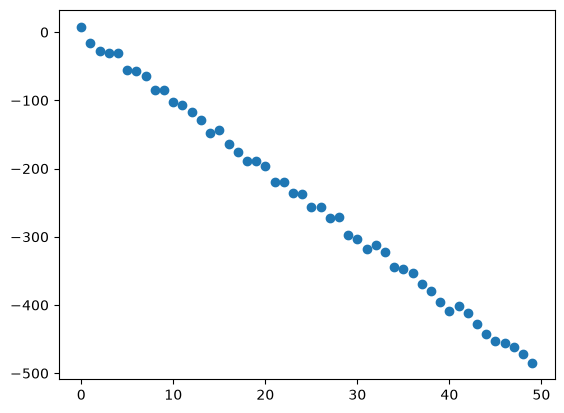

In [16]:
data_4 = pd.DataFrame()
data_4["X"] = np.arange(50)
delta = np.random.uniform(-10, 10, data_4["X"].size)
data_4["Y"] = -10 * data_4["X"] + delta

plt.scatter(y=data_4["Y"], x=data_4["X"]);

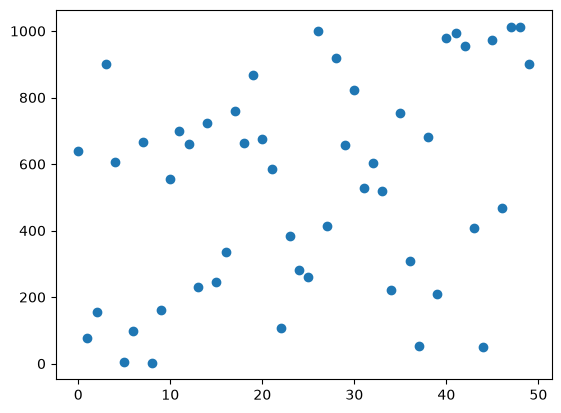

In [17]:
data_5 = pd.DataFrame()
data_5["X"] = np.arange(50)
delta = np.random.uniform(-10, 1000, data_5["X"].size)
data_5["Y"] = data_5["X"] + delta

plt.scatter(y=data_5["Y"], x=data_5["X"]);

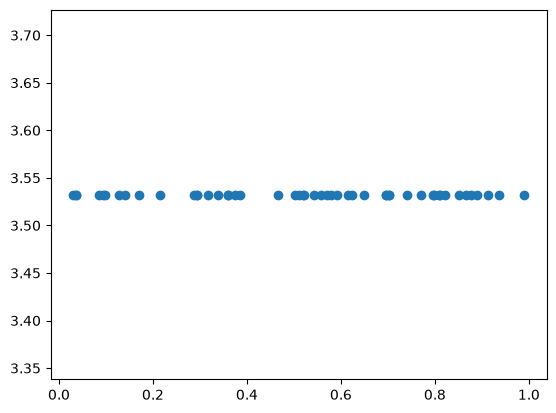

In [18]:
data_6 = pd.DataFrame()
data_6["X"] = np.random.rand(50)
delta = np.random.uniform(1, data_6["X"].size)
data_6["Y"] = delta

plt.scatter(y=data_6["Y"], x=data_6["X"]);

### **Covariance**
Measures the joint variability of two quantitative variables.

$cov(X, Y) = \frac{\sum_{i=1}^n(X_i-\overline{X})(Y_i-\overline{Y})}{n - 1}$

`NOTE:` *Covariance depends on the units of the variables, which makes it hard to tell whether a value is high or low. Correlation solves this issue.*

In [19]:
data_1.cov()

,X,Y
X,212.500000,2119.842966
Y,2119.842966,21180.240731


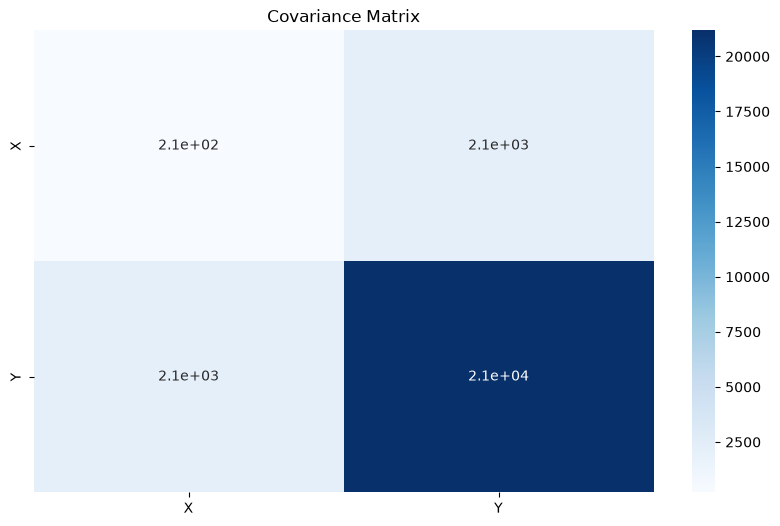

In [20]:
# Plot covariance matrix
plt.figure(figsize=(10, 6))
plt.title("Covariance Matrix")

sns.heatmap(data_1.cov(), cmap='Blues', annot=True)
plt.show()

### **Pearson Correlation**

$\rho = \frac{cov(X, Y)}{S_X S_Y}$

$\rho = -1$ perfect negative correlation <p>
$\rho = 0$ no linear correlation <p>
$\rho = 1$ perfect positive correlation <p>

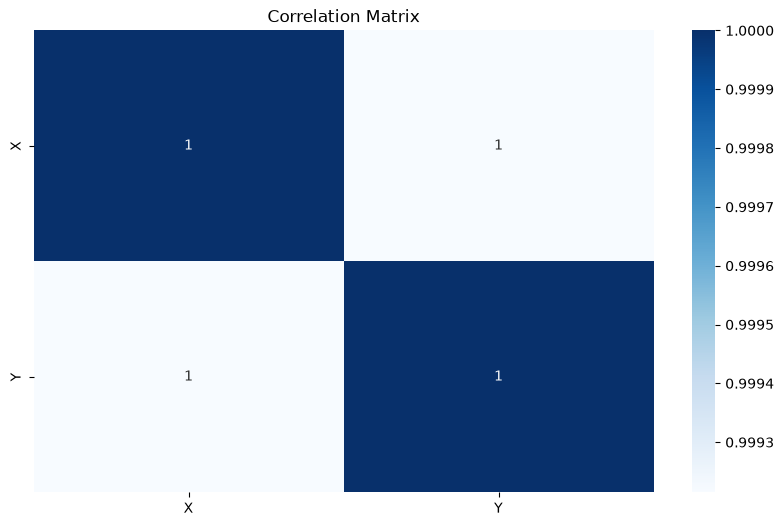

In [21]:
# Plot correlation matrix
plt.figure(figsize=(10, 6))
plt.title("Correlation Matrix")

sns.heatmap(data_1.corr(), cmap='Blues', annot=True)
plt.show()